# Определение орбиты методом Лапласа

Ноутбук по шагам вычисляет предварительную гелиоцентрическую орбиту астероида по серии его
топоцентрических положений (α, δ) за одну ночь методом Лапласа.

**Тест.** «Наблюдения» сначала берутся из эфемериды astEph, то есть из точной модели без шума.
Поэтому полученную орбиту можно сравнить с элементами из `MPCORB.DAT`, по которым считалась
эфемерида. Затем проверяется, как метод переносит шум измерений (раздел 11), и он применяется
к реальным измерениям серии 20260929 (раздел 12).

**Обозначения** (как в `lagrange_rd.tex`). Все векторы — в экваториальной системе J2000,
единицы — а.е. и сутки.

| | |
|---|---|
| $\mathbf D(t)$ | единичный вектор направления от наблюдателя на астероид |
| $d(t)$ | топоцентрическое расстояние до астероида |
| $\mathbf g(t)$ | гелиоцентрический радиус-вектор наблюдателя (из astEph `--observer`) |
| $\mathbf r = \mathbf g + d\,\mathbf D$ | гелиоцентрический радиус-вектор астероида, $r = |\mathbf r|$ |
| $\mu = k^2$ | гравитационный параметр Солнца, а.е.³/сут² |
| точки над буквой | производные по времени в момент $t_0$ |

**Разделы:**
1. Параметры.
2. Наблюдения.
3. Векторы $\mathbf D_i$ и их полиномиальная аппроксимация: $\mathbf D,\dot{\mathbf D},\ddot{\mathbf D}$ в момент $t_0$.
4. Положение, скорость и ускорение наблюдателя $\mathbf g,\dot{\mathbf g},\ddot{\mathbf g}$.
5. Уравнения Лапласа.
6. Уравнение Лагранжа для $r$ и выбор корня.
7. Скорость $\dot d$, векторы $\mathbf r,\dot{\mathbf r}$ и световое запаздывание.
8. Элементы орбиты и сравнение с MPCORB.
9. Проверка: O-C по полученной орбите.
10. Влияние степени полинома.
11. Влияние шума измерений.
12. Реальные измерения.

In [18]:
from math import *
import numpy as np

import pandas as pd

import os
import subprocess
from concurrent.futures import ThreadPoolExecutor

from astropy.time import Time

import matplotlib
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except NameError:
    pass # запуск как обычный .py-скрипт
import matplotlib.pyplot as plt
SERIES_COLORS = ['#2a78d6', '#eb6834'] # 1-й и 2-й цвета проверенной категориальной палитры

## 1. Параметры

Тестовая серия повторяет реальную: 10 моментов через 5 минут, начиная с первого кадра серии
20260929 (астероид 24445, обсерватория 217 — Ассы-Тургень). Время везде UTC (JD).

In [2]:
ASTEPH_DIR = '/Users/ymax/Documents/coding/claude/nea_orb/astEph' # локальная программа astEph с MPCORB.DAT
ASTEPH_RATE_STEP = 300.0    # с - шаг численного дифференцирования для скоростей из astEph
ASTID = '24445'             # астероид (номер или обозначение, как в MPCORB.DAT)
LOCATION = '217'            # код обсерватории MPC (astEph знает только 217)
N = 10                      # число моментов наблюдений в тесте
STEP_MIN = 5.0              # мин - интервал между ними
t = Time('2026-09-29T15:35:23.153', format='isot', scale='utc')
JD = t.jd + STEP_MIN*np.arange(N)/1440.0

POLY_DEG = 2                # степень полинома для D(t), >= 2 (сравнение степеней - раздел 10)
MU = 2.9591220828411956E-04 # а.е.^3/сут^2 - GM Солнца (как _GMS в astEph, = k^2)
C_AU_DAY = 299792.458*86400/1.495978707E+08 # скорость света, а.е./сут
EPS_J2000 = np.radians(23.43929111)         # наклон эклиптики J2000 (как в astEph)

REAL_FILE = '/Users/ymax/Documents/coding/claude/nea_orb/24445_20260929_radec.csv' # реальные измерения (раздел 11): JD, RA, DEC, ERR_RA, ERR_DEC
JD

array([2461313.14957353, 2461313.15304575, 2461313.15651797,
       2461313.1599902 , 2461313.16346242, 2461313.16693464,
       2461313.17040686, 2461313.17387909, 2461313.17735131,
       2461313.18082353])

## Функции доступа к astEph

- **`get_asteph_ephemeris(target, JD, location)`** — топоцентрическая астрометрическая эфемерида
  (α, δ в градусах) на моменты JD. Так же она устроена в ноутбуках астрометрии. В тесте эта
  эфемерида играет роль наблюдений. Она учитывает световое запаздывание: направление
  соответствует положению астероида в момент $t - d/c$.
- **`get_observer_state(JD, location)`** — гелиоцентрические $\mathbf g,\dot{\mathbf g},\ddot{\mathbf g}$
  наблюдателя (а.е., а.е./сут, а.е./сут²), режим `astEph --observer`.

In [3]:
def _run_asteph(target, jd, location):
    """Один вызов astEph: (RA, DEC в градусах, V) на момент jd (UTC) для обсерватории location."""
    exe = os.path.join(ASTEPH_DIR, 'astEph')
    out = subprocess.run([exe, str(target), f'{jd:.8f}', f'obscode={location}'], cwd=ASTEPH_DIR,
                         capture_output=True, text=True, timeout=120)
    if out.returncode != 0:
        raise RuntimeError(f'astEph: {out.stderr.strip() or out.stdout.strip()}')
    val = {l.split('=')[0].strip(): l.split('=', 1)[1].split()[0] for l in out.stdout.splitlines() if '=' in l}
    return np.degrees(float(val['RA'])), np.degrees(float(val['DEC'])), float(val['Vmag'])

def get_asteph_ephemeris(target, JD, location):
    """Та же эфемерида, что get_horizons_ephemeris, но из локальной программы astEph (ASTEPH_DIR).
    astEph дает только положение и V, поэтому скорости считаются по положениям в моменты
    jd -+ ASTEPH_RATE_STEP (с), а DELTA не заполняется. Первый вызов делается отдельно: при новой
    эпохе MPCORB.DAT astEph сначала считает и сохраняет свой кэш интегрирования (~10 с). Остальные
    вызовы идут параллельно."""
    JD = np.atleast_1d(np.asarray(JD, dtype=float))
    if not os.path.isfile(os.path.join(ASTEPH_DIR, 'astEph')):
        raise FileNotFoundError(f'нет программы {ASTEPH_DIR}/astEph (сборка: cc -O2 -o astEph astEph.c -lm)')
    h = ASTEPH_RATE_STEP/86400
    jds = np.concatenate([JD, JD-h, JD+h])
    first = _run_asteph(target, jds[0], location)
    with ThreadPoolExecutor(max_workers=8) as ex:
        rest = list(ex.map(lambda jd: _run_asteph(target, jd, location), jds[1:]))
    res = np.array([first] + rest).reshape(3, len(JD), 3)
    (ra, dec, v), (ra1, dec1, _), (ra2, dec2, _) = [res[k].T for k in range(3)]
    dra = ((ra2-ra1+180) % 360 - 180)*np.cos(np.radians(dec))*3600/(2*ASTEPH_RATE_STEP/3600)
    ddec = (dec2-dec1)*3600/(2*ASTEPH_RATE_STEP/3600)
    return pd.DataFrame(dict(JD=JD, RA_EPH=ra, DEC_EPH=dec, dRAcosD=dra, dDEC=ddec, # arcsec/hour
                             VMAG=v, DELTA=np.nan))

def get_observer_state(JD, location='217', asteph_dir=ASTEPH_DIR):
    """Гелиоцентрические положение R (а.е.), скорость V (а.е./сут) и ускорение A (а.е./сут^2)
    наблюдателя в обсерватории с кодом MPC location на момент JD (UTC), экваториальная система J2000.
    Считает программа astEph (режим --observer). Возвращает три numpy-массива по 3 компоненты."""
    out = subprocess.run([os.path.join(asteph_dir, 'astEph'), '--observer', f'{float(JD):.8f}',
                          f'obscode={location}'], cwd=asteph_dir, capture_output=True, text=True, timeout=300)
    if out.returncode != 0:
        raise RuntimeError(f'astEph: {out.stderr.strip() or out.stdout.strip()}')
    val = {k.strip(): v for k, v in (l.split('=', 1) for l in out.stdout.splitlines() if '=' in l)}
    R, V, A = (np.array(val[k].split(), dtype=float) for k in ('R', 'V', 'A'))
    return R, V, A

## 2. Наблюдения

В тесте наблюдения — это эфемерида astEph на моменты `JD`: топоцентрические астрометрические α, δ
(J2000) без шума. В разделе 11 вместо них подставляются реальные измерения.

In [4]:
pos = get_asteph_ephemeris(ASTID, JD, LOCATION)
obs = pd.DataFrame(dict(JD=pos['JD'], RA=pos['RA_EPH'], DEC=pos['DEC_EPH'])) # градусы
print(f"дуга {(obs['JD'].iloc[-1]-obs['JD'].iloc[0])*1440:.0f} мин, {len(obs)} положений; "
      f"видимое движение {hypot(pos['dRAcosD'].mean(), pos['dDEC'].mean()):.1f}\"/ч")
obs

дуга 45 мин, 10 положений; видимое движение 73.0"/ч


,JD,RA,DEC
0,2.461313e+06,296.515013,11.887703
1,2.461313e+06,296.515278,11.886034
2,2.461313e+06,296.515544,11.884365
3,2.461313e+06,296.515811,11.882696
4,2.461313e+06,296.516078,11.881026
5,2.461313e+06,296.516346,11.879357
6,2.461313e+06,296.516615,11.877687
7,2.461313e+06,296.516885,11.876016
8,2.461313e+06,296.517155,11.874346
9,2.461313e+06,296.517426,11.872675


## 3. Векторы направления и их производные

Каждое положение переводится в единичный вектор
$$\mathbf D_i = (\cos\alpha_i\cos\delta_i,\ \sin\alpha_i\cos\delta_i,\ \sin\delta_i).$$

Каждая компонента $\mathbf D$ аппроксимируется методом наименьших квадратов полиномом степени $n$
по $x = t - t_0$, где $t_0$ — средний момент серии:
$$D_j(t) = \sum_{k=0}^{n} c_{jk}\,x^k \quad\Rightarrow\quad
D_j(t_0) = c_{j0},\quad \dot D_j(t_0) = c_{j1},\quad \ddot D_j(t_0) = 2c_{j2}.$$

Полином не сохраняет длину вектора в точности, поэтому $\mathbf D(t_0)$ нормируется на единицу.
Уравнения ниже считают $|\mathbf D| = 1$.

**Качество аппроксимации** контролируется невязками. Для каждого момента считается разность
аппроксимированного и наблюдённого направления. Она раскладывается на α·cosδ (проекция на
орт $\mathbf e_\alpha = (-\sin\alpha, \cos\alpha, 0)$) и δ (проекция на орт
$\mathbf e_\delta = (-\sin\delta\cos\alpha, -\sin\delta\sin\alpha, \cos\delta)$), в секундах дуги.

Главная трудность метода — вторая производная $\ddot{\mathbf D}$. Это кривизна видимого пути,
и на короткой дуге она мала и чувствительна к шуму (разделы 11–12).

In [5]:
def direction_vectors(ra_deg, dec_deg):
    """Единичные векторы направления (N x 3) по RA, DEC в градусах."""
    ra, dec = np.radians(np.asarray(ra_deg)), np.radians(np.asarray(dec_deg))
    return np.column_stack([np.cos(ra)*np.cos(dec), np.sin(ra)*np.cos(dec), np.sin(dec)])

def analyze_vector_D(jd, Dv, n, jd0=None):
    """Полином степени n по x = jd - jd0 для каждой компоненты D (МНК). Возвращает jd0, D (нормированный),
    dD/dt, d2D/dt2 в момент jd0 и невязки аппроксимации (arcsec) по RA*cos(DEC) и DEC."""
    if n < 2:
        raise ValueError('степень полинома должна быть >= 2: иначе d2D/dt2 = 0 и задача вырождается (C = 0)')
    if len(jd) < n + 2:
        raise ValueError(f'для степени {n} нужно хотя бы {n+2} наблюдений (сейчас {len(jd)})')
    jd = np.asarray(jd, dtype=float)
    jd0 = jd.mean() if jd0 is None else jd0
    x = jd - jd0
    X = np.column_stack([x**k for k in range(n+1)])
    Cf = np.linalg.lstsq(X, Dv, rcond=None)[0]          # (n+1) x 3
    D = Cf[0]/np.linalg.norm(Cf[0])
    dotD = Cf[1] if n >= 1 else np.zeros(3)
    ddotD = 2*Cf[2] if n >= 2 else np.zeros(3)
    dres = X @ Cf - Dv                                  # аппроксимация минус наблюдение
    ra, dec = np.arctan2(Dv[:,1], Dv[:,0]), np.arcsin(Dv[:,2])
    e_ra = np.column_stack([-np.sin(ra), np.cos(ra), np.zeros_like(ra)])
    e_dec = np.column_stack([-np.sin(dec)*np.cos(ra), -np.sin(dec)*np.sin(ra), np.cos(dec)])
    res = np.degrees(np.column_stack([(dres*e_ra).sum(1), (dres*e_dec).sum(1)]))*3600
    return jd0, D, dotD, ddotD, res

Dv = direction_vectors(obs['RA'], obs['DEC'])
JD0, D, dotD, ddotD, fit_res = analyze_vector_D(obs['JD'], Dv, POLY_DEG)
print(f'JD0 = {JD0:.6f} ({Time(JD0, format="jd", scale="utc").isot} UTC), степень полинома {POLY_DEG}')
print('D     =', D)
print('dD/dt =', dotD, '  1/сут')
print('d2D/dt2 =', ddotD, '  1/сут^2')
print(f'невязки аппроксимации: RA*cos(DEC) {np.std(fit_res[:,0]):.2e}", DEC {np.std(fit_res[:,1]):.2e}"')

JD0 = 2461313.165199 (2026-09-29T15:57:53.153 UTC), степень полинома 2
D     = [ 0.43688814 -0.87564148  0.20586588]
dD/dt = [ 0.00195168 -0.00095721 -0.0082133 ]   1/сут
d2D/dt2 = [ 0.00092409  0.00046173 -0.0003478 ]   1/сут^2
невязки аппроксимации: RA*cos(DEC) 2.26e-04", DEC 2.75e-05"


## 4. Положение, скорость и ускорение наблюдателя

$\mathbf g,\dot{\mathbf g},\ddot{\mathbf g}$ на момент $t_0$ дает astEph `--observer`. Это сумма двух частей:
- **центр Земли** относительно Солнца — из N-тельной модели astEph;
- **наблюдатель** относительно центра Земли — вращение вокруг оси Земли с суточной угловой скоростью.

Обе части в той же системе J2000.

В $\ddot{\mathbf g}$ преобладает **суточное вращение**: центростремительное ускорение наблюдателя
$\omega^2\rho\cos\varphi' R_\oplus$ в несколько раз больше ускорения Земли к Солнцу. На дуге в одну
ночь именно оно дает основную кривизну видимого пути. Фактически метод определяет расстояние
по суточному параллаксу.

In [6]:
g, dot_g, ddot_g = get_observer_state(JD0, location=LOCATION, asteph_dir=ASTEPH_DIR)
a_sun = -MU*g/np.linalg.norm(g)**3 # ускорение Земли к Солнцу (для сравнения)
print('g      =', g, ' а.е.')
print('dg/dt  =', dot_g, ' а.е./сут')
print('d2g/dt2 =', ddot_g, ' а.е./сут^2')
print(f'|d2g/dt2| = {np.linalg.norm(ddot_g):.3e}, из них притяжение Солнца {np.linalg.norm(a_sun):.3e} а.е./сут^2, '
      f'суточное вращение ~ {np.linalg.norm(ddot_g-a_sun):.3e}')

g      = [0.99594586 0.09856571 0.04275358]  а.е.
dg/dt  = [-0.00200814  0.01579159  0.00677491]  а.е./сут
d2g/dt2 = [-1.30938116e-03  6.73224227e-04 -9.29615479e-06]  а.е./сут^2
|d2g/dt2| = 1.472e-03, из них притяжение Солнца 2.949e-04 а.е./сут^2, суточное вращение ~ 1.235e-03


## 5. Уравнения Лапласа

Гелиоцентрический радиус-вектор астероида $\mathbf r = \mathbf g + d\,\mathbf D$ дважды дифференцируется
по времени:
$$\ddot{\mathbf r} = \ddot{\mathbf g} + \ddot d\,\mathbf D + 2\dot d\,\dot{\mathbf D} + d\,\ddot{\mathbf D}.$$

В задаче двух тел $\ddot{\mathbf r} = -\mu\,\mathbf r/r^3$. Возмущения от планет на дуге в одну ночь
пренебрежимы. Отсюда
$$\ddot d\,\mathbf D + 2\dot d\,\dot{\mathbf D} + d\,\ddot{\mathbf D} = -\ddot{\mathbf g} - \frac{\mu}{r^3}(\mathbf g + d\,\mathbf D).$$

**Расстояние.** Скалярное умножение на $\mathbf D\times\dot{\mathbf D}$ убирает члены с $\ddot d$ и $\dot d$:
$$C\,d = C_2 + C_3\,r^{-3},\qquad
C = \ddot{\mathbf D}\cdot(\mathbf D\times\dot{\mathbf D}) = [\mathbf D,\dot{\mathbf D},\ddot{\mathbf D}],\quad
C_2 = -\ddot{\mathbf g}\cdot(\mathbf D\times\dot{\mathbf D}),\quad
C_3 = -\mu\,\mathbf g\cdot(\mathbf D\times\dot{\mathbf D}).$$

Здесь $C$ — смешанное произведение, то есть кривизна видимого пути. Когда $C\to 0$ (путь почти
прямой), задача вырождается.

**Геометрия треугольника Солнце–наблюдатель–астероид:**
$$r^2 = d^2 + 2C_1 d + C_0,\qquad C_1 = \mathbf g\cdot\mathbf D,\quad C_0 = \mathbf g\cdot\mathbf g.$$

**Скорость.** Умножение на $\mathbf D\times\ddot{\mathbf D}$ убирает $\ddot d$ и $d$
(учтено $\dot{\mathbf D}\cdot(\mathbf D\times\ddot{\mathbf D}) = -C$):
$$\dot d = \frac{\ddot{\mathbf g}\cdot(\mathbf D\times\ddot{\mathbf D}) + \mu r^{-3}\,\mathbf g\cdot(\mathbf D\times\ddot{\mathbf D})}{2C}.$$

In [7]:
def laplace_coefficients(D, dotD, ddotD, g, ddot_g):
    """Коэффициенты уравнений C d = C2 + C3 r^-3 и r^2 = d^2 + 2 C1 d + C0."""
    DxdD = np.cross(D, dotD)
    return dict(C=ddotD @ DxdD, C0=g @ g, C1=g @ D, C2=-ddot_g @ DxdD, C3=-MU*(g @ DxdD))

coef = laplace_coefficients(D, dotD, ddotD, g, ddot_g)
pd.Series(coef)

C     0.000008
C0    1.003451
C1    0.357610
C2    0.000007
C3   -0.000002
dtype: float64

## 6. Уравнение Лагранжа и выбор корня

Из первого уравнения $d = \alpha + \beta r^{-3}$, где $\alpha = C_2/C$ и $\beta = C_3/C$. Подстановка во
второе уравнение дает уравнение Лагранжа (вывод — в `lagrange_rd.tex`):
$$r^8 + a\,r^6 + b\,r^3 + c = 0,\qquad a = -(\alpha^2 + 2C_1\alpha + C_0),\quad b = -2\beta(\alpha + C_1),\quad c = -\beta^2.$$

**Свойства корней:**
- Поскольку $c<0$, положительный корень существует всегда.
- По правилу Декарта положительных корней 1 или 3. Это неоднозначность Шарлье.
- Физическое решение должно удовлетворять $r>0$ и $d>0$.
- Ложный корень соответствует самому наблюдателю: $d\approx 0$, $r\approx|\mathbf g|$. Он отбрасывается
  порогом `D_MIN`.
- Если остается больше одного решения, печатаются все, а выбирается первое. Выбор можно изменить
  параметром `ROOT_INDEX`.

In [8]:
D_MIN = 1e-4     # а.е. (~15000 км) - решения ближе к наблюдателю считаются ложными
ROOT_INDEX = 0   # какое из оставшихся решений брать, если их несколько

def solve_rd(C, C0, C1, C2, C3):
    """Все положительные вещественные корни уравнения Лагранжа и соответствующие d (из lagrange_rd.tex)."""
    al, be = C2 / C, C3 / C
    a = -(al**2 + 2*C1*al + C0)
    b = -2*be*(al + C1)
    c = -be**2
    roots = np.roots([1, 0, a, 0, 0, b, 0, 0, c]) # коэффициенты при r^8, r^7, ..., r^0
    sols = []
    for r in roots:
        if abs(r.imag) < 1e-10 and r.real > 0:
            r = r.real
            sols.append((r, al + be / r**3))
    return sorted(sols)

sols = solve_rd(**coef)
for r_, d_ in sols:
    print(f'r = {r_:.6f} а.е., d = {d_:+.6f} а.е.' + ('' if d_ > D_MIN else '  <- отброшено (d <= D_MIN)'))
good = [(r_, d_) for r_, d_ in sols if d_ > D_MIN]
if not good:
    raise RuntimeError('нет физического решения (d > D_MIN)')
r, d = good[min(ROOT_INDEX, len(good)-1)]
print(f'выбрано: r = {r:.6f} а.е., d = {d:.6f} а.е.')

r = 1.458302 а.е., d = +0.760906 а.е.
выбрано: r = 1.458302 а.е., d = 0.760906 а.е.


## 7. Векторы положения и скорости. Световое запаздывание

- **Скорость $\dot d$** — по формуле раздела 5.
- **Векторы:**
$$\mathbf r = \mathbf g + d\,\mathbf D,\qquad \dot{\mathbf r} = \dot{\mathbf g} + \dot d\,\mathbf D + d\,\dot{\mathbf D}.$$
- **Эпоха.** Наблюдаемое направление соответствует положению астероида в момент вылета света,
  поэтому $\mathbf r,\dot{\mathbf r}$ относятся к эпохе $t_0 - d/c$, а не к $t_0$. Есть еще поправка
  к производным, множитель $1-\dot d/c \sim 10^{-4}$. Для предварительной орбиты она не нужна.
- **Шкала времени эпохи** — UTC (как у наблюдений). От TT она отличается на 69 с, что для элементов
  пренебрежимо.

In [9]:
def laplace_state(D, dotD, ddotD, g, dot_g, ddot_g, r, d, coef):
    """dd/dt и гелиоцентрические векторы положения и скорости астероида."""
    DxddD = np.cross(D, ddotD)
    dot_d = (ddot_g @ DxddD + MU/r**3*(g @ DxddD))/(2*coef['C'])
    return dot_d, g + d*D, dot_g + dot_d*D + d*dotD

dot_d, r_vec, v_vec = laplace_state(D, dotD, ddotD, g, dot_g, ddot_g, r, d, coef)
JD_EPOCH = JD0 - d/C_AU_DAY
print(f'dd/dt = {dot_d:+.6f} а.е./сут, световое запаздывание {d/C_AU_DAY*86400:.1f} с, эпоха JD {JD_EPOCH:.6f} UTC')
print('r =', r_vec, f' а.е. (|r| = {np.linalg.norm(r_vec):.6f}, из уравнения Лагранжа r = {r:.6f})')
print('v =', v_vec, ' а.е./сут')

dd/dt = -0.001586 а.е./сут, световое запаздывание 379.7 с, эпоха JD 2461313.160804 UTC
r = [ 1.32837675 -0.56771533  0.1993982 ]  а.е. (|r| = 1.458302, из уравнения Лагранжа r = 1.458302)
v = [-0.00121607  0.01645215  0.00019882]  а.е./сут


## 8. Элементы орбиты и сравнение с MPCORB

Векторы поворачиваются из экваториальной системы J2000 в эклиптическую поворотом на $\varepsilon$ вокруг оси $x$.
Затем элементы находятся стандартно:
- **большая полуось** — из интеграла энергии: $v^2/2 - \mu/r = -\mu/(2a)$;
- **эксцентриситет** — модуль вектора Лапласа–Рунге–Ленца $\mathbf e = \dot{\mathbf r}\times\mathbf h/\mu - \mathbf r/r$;
- **наклон и узел** — по вектору площадей $\mathbf h = \mathbf r\times\dot{\mathbf r}$;
- **аргумент перигелия** — угол от узла до $\mathbf e$;
- **средняя аномалия** — через эксцентрическую аномалию.

Для сравнения из `MPCORB.DAT` читается строка того же астероида. Ее средняя аномалия переносится
на нашу эпоху со средним движением $n$ из той же строки. Остальные элементы на дуге в месяцы
меняются мало (возмущения), поэтому сравниваются как есть.

In [10]:
def orbital_elements(r_eq, v_eq):
    """Гелиоцентрические элементы (эклиптика и равноденствие J2000) по векторам в экваториальной системе.
    a в а.е., углы в градусах; для гиперболы M = nan."""
    ce, se = np.cos(EPS_J2000), np.sin(EPS_J2000)
    Rot = np.array([[1, 0, 0], [0, ce, se], [0, -se, ce]])
    rv, vv = Rot @ r_eq, Rot @ v_eq
    rn = np.linalg.norm(rv)
    h = np.cross(rv, vv)
    a = 1/(2/rn - vv @ vv/MU)
    ev = np.cross(vv, h)/MU - rv/rn
    e = np.linalg.norm(ev)
    inc = degrees(acos(h[2]/np.linalg.norm(h)))
    node = np.cross([0, 0, 1], h)
    Om = degrees(atan2(node[1], node[0])) % 360
    w = degrees(acos(np.clip(node @ ev/np.linalg.norm(node)/e, -1, 1)))
    w = w if ev[2] >= 0 else 360 - w
    nu = acos(np.clip(ev @ rv/e/rn, -1, 1))
    nu = nu if rv @ vv >= 0 else 2*pi - nu
    if e < 1:
        E = 2*atan(sqrt((1-e)/(1+e))*tan(nu/2))
        M = degrees(E - e*sin(E)) % 360
    else:
        M = np.nan
    return dict(a=a, e=e, i=inc, Node=Om, Peri=w, M=M)

def _unpack_mpc_epoch(s):
    """Упакованная эпоха MPC (напр. K2669) -> JD (TT, 0h)."""
    dig = lambda c: int(c) if c.isdigit() else ord(c) - ord('A') + 10
    year = (ord(s[0]) - ord('A') + 10)*100 + int(s[1:3])
    return Time(f'{year:04d}-{dig(s[3]):02d}-{dig(s[4]):02d}', scale='tt').jd

def read_mpcorb(target, path=os.path.join(ASTEPH_DIR, 'MPCORB.DAT')):
    """Элементы астероида target из MPCORB.DAT (номер ищется как '(номер)' в читаемом обозначении)."""
    key = str(target).strip()
    with open(path, errors='replace') as f:
        for line in f:
            name = line[166:194].strip() if len(line) > 190 else ''
            if name and (name.startswith(f'({key})') or name == key or name.split(')')[-1].strip() == key):
                return dict(epoch=_unpack_mpc_epoch(line[20:25]), M=float(line[26:35]), Peri=float(line[37:46]),
                            Node=float(line[48:57]), i=float(line[59:68]), e=float(line[70:79]),
                            n=float(line[80:91]), a=float(line[92:103]), line=line.rstrip())
    raise KeyError(f'{target} не найден в {path}')

el = orbital_elements(r_vec, v_vec)
mpc = read_mpcorb(ASTID)
mpc_M = (mpc['M'] + mpc['n']*(JD_EPOCH - mpc['epoch'])) % 360 # перенос M на нашу эпоху
cmp = pd.DataFrame({'Лаплас': el, 'MPCORB': {k: (mpc_M if k == 'M' else mpc[k]) for k in el}})
cmp['разность'] = cmp['Лаплас'] - cmp['MPCORB']
print(f"эпоха JD {JD_EPOCH:.5f}; MPCORB: эпоха элементов JD {mpc['epoch']:.1f}, M перенесена на нашу эпоху")
cmp

эпоха JD 2461313.16080; MPCORB: эпоха элементов JD 2461200.5, M перенесена на нашу эпоху


,Лаплас,MPCORB,разность
a,2.214254,2.210943,0.003312
e,0.546271,0.545700,0.000571
i,23.786165,23.769070,0.017095
Node,203.104783,203.134910,-0.030127
Peri,219.111040,219.122640,-0.011600
M,333.113497,333.051130,0.062367


## 9. Проверка: O-C по полученной орбите

По найденным элементам (задача двух тел) на каждый момент наблюдения считается топоцентрическое
направление, с итерациями по световому запаздыванию. Положение наблюдателя $\mathbf g(t_i)$ берется
из astEph. Невязки O-C показывают, насколько орбита воспроизводит исходные наблюдения на этой дуге.

Малые O-C еще не гарантируют правильную орбиту. На короткой дуге наблюдениям удовлетворяют и
далекие от истины орбиты (разделы 11–12). Поэтому O-C — проверка вычислений, а не точности орбиты.

In [11]:
def kepler_position(el, jd_epoch, jd):
    """Гелиоцентрическое положение (экваториальная J2000, а.е.) на момент jd по эллиптическим элементам."""
    a, e = el['a'], el['e']
    i, Om, w = np.radians([el['i'], el['Node'], el['Peri']])
    M = np.radians(el['M']) + sqrt(MU/a**3)*(jd - jd_epoch)
    E = M
    for _ in range(50): # уравнение Кеплера, Ньютон
        E -= (E - e*sin(E) - M)/(1 - e*cos(E))
    xp, yp = a*(cos(E) - e), a*sqrt(1 - e*e)*sin(E)
    cO, sO, ci, si, cw, sw = cos(Om), sin(Om), cos(i), sin(i), cos(w), sin(w)
    x = (cO*cw - sO*sw*ci)*xp + (-cO*sw - sO*cw*ci)*yp
    y = (sO*cw + cO*sw*ci)*xp + (-sO*sw + cO*cw*ci)*yp
    z = (sw*si)*xp + (cw*si)*yp
    ce, se = np.cos(EPS_J2000), np.sin(EPS_J2000)
    return np.array([x, ce*y - se*z, se*y + ce*z])

def omc(el, jd_epoch, obs, location=LOCATION):
    """O-C (arcsec) наблюдений obs (JD, RA, DEC) относительно орбиты el."""
    rows = []
    for jd, ra, dec in zip(obs['JD'], obs['RA'], obs['DEC']):
        go = get_observer_state(jd, location)[0]
        tau = 0.0
        for _ in range(5): # световое запаздывание
            rho = kepler_position(el, jd_epoch, jd - tau) - go
            tau = np.linalg.norm(rho)/C_AU_DAY
        ra_c, dec_c = degrees(atan2(rho[1], rho[0])) % 360, degrees(asin(rho[2]/np.linalg.norm(rho)))
        rows.append(dict(JD=jd, OMC_RA=((ra - ra_c + 180) % 360 - 180)*cos(radians(dec))*3600,
                         OMC_DEC=(dec - dec_c)*3600))
    return pd.DataFrame(rows)

res = omc(el, JD_EPOCH, obs)
print(f"O-C: RA*cos(DEC) {res['OMC_RA'].mean():+.3f}\" +- {res['OMC_RA'].std():.3f}\", "
      f"DEC {res['OMC_DEC'].mean():+.3f}\" +- {res['OMC_DEC'].std():.3f}\"")
res

O-C: RA*cos(DEC) +0.000" +- 0.001", DEC -0.000" +- 0.000"


,JD,OMC_RA,OMC_DEC
0,2.461313e+06,0.001108,0.000221
1,2.461313e+06,0.000855,0.000171
2,2.461313e+06,0.000603,0.000121
3,2.461313e+06,0.000370,0.000078
4,2.461313e+06,0.000121,0.000026
5,2.461313e+06,-0.000125,-0.000025
6,2.461313e+06,-0.000370,-0.000079
7,2.461313e+06,-0.000596,-0.000122
8,2.461313e+06,-0.000838,-0.000177
9,2.461313e+06,-0.001077,-0.000231


## Весь расчет одной функцией

Шаги разделов 3–8 собраны в функцию `laplace_orbit`. Она нужна для сравнений в следующих разделах.
Состояние наблюдателя можно передать готовым (`observer`), чтобы при многократных расчетах на
один и тот же момент не вызывать astEph каждый раз.

In [12]:
def laplace_orbit(obs, n=POLY_DEG, location=LOCATION, observer=None, jd0=None):
    """Метод Лапласа по наблюдениям obs (JD, RA, DEC в градусах). Возвращает dict: jd0, коэффициенты,
    все решения, выбранные r, d, dd/dt, векторы, эпоху и элементы (None, если физического решения нет)."""
    jd0_, D, dotD, ddotD, fit_res = analyze_vector_D(obs['JD'], direction_vectors(obs['RA'], obs['DEC']), n, jd0)
    g, dot_g, ddot_g = observer if observer is not None else get_observer_state(jd0_, location)
    coef = laplace_coefficients(D, dotD, ddotD, g, ddot_g)
    sols = solve_rd(**coef)
    out = dict(jd0=jd0_, coef=coef, sols=sols, fit_res=fit_res, el=None)
    good = [(r_, d_) for r_, d_ in sols if d_ > D_MIN]
    if good:
        r_, d_ = good[min(ROOT_INDEX, len(good)-1)]
        dot_d, rv, vv = laplace_state(D, dotD, ddotD, g, dot_g, ddot_g, r_, d_, coef)
        out.update(r=r_, d=d_, dot_d=dot_d, r_vec=rv, v_vec=vv, epoch=jd0_ - d_/C_AU_DAY,
                   el=orbital_elements(rv, vv))
    return out

## 10. Влияние степени полинома

Степень $n$ — компромисс:
- при малой $n$ (2) полином хуже описывает истинную кривую (систематическая ошибка);
- при большой $n$ производные в $t_0$ хуже определены (усиление шума).

На точных данных видна только первая часть. Здесь сравниваются $n = 2, 3, 4$.

**Чем длиннее дуга, тем выше нужна степень.** На дуге в час истинная кривая почти парабола, и $n = 2$
достаточно. На дуге в несколько часов растут члены высших порядков, и $n$ стоит увеличивать до 3–4,
следя за невязками аппроксимации и за тем, чтобы точек было заметно больше, чем $n+1$.

Для дуги в несколько ночей одного повышения степени в этой (топоцентрической) постановке
недостаточно. Суточное вращение наблюдателя добавляет в $\mathbf D(t)$ колебание с периодом сутки,
которое полином невысокой степени не описывает (см. выводы).

In [13]:
obs_state0 = get_observer_state(JD0, LOCATION)
rows = []
for n in (2, 3, 4):
    o = laplace_orbit(obs, n=n, observer=obs_state0)
    rows.append(dict(n=n, C=o['coef']['C'], d=o.get('d'), **(o['el'] or {})))
pd.DataFrame(rows).set_index('n')

,C,d,a,e,i,Node,Peri,M
n,,,,,,,,
2,0.000008,0.760906,2.214254,0.546271,23.786165,203.104783,219.111040,333.113497
3,0.000008,0.760905,2.214194,0.546269,23.786108,203.104898,219.113572,333.111964
4,0.000008,0.760358,2.212708,0.546005,23.772230,203.126690,219.100697,333.092375


## 11. Влияние шума измерений

К точным положениям добавляется гауссов шум с СКО σ по α·cosδ и δ, и метод повторяется 200 раз.
Таблица показывает медиану и устойчивый разброс (интерквартильный размах / 1.35) для $d$, $a$, $e$, $i$,
а также долю эллиптических решений.

Это главный тест применимости. Кривизна видимого пути за час очень мала, и шум в сотые доли
секунды дуги уже заметно искажает $\ddot{\mathbf D}$.

In [14]:
rng = np.random.default_rng(1)
N_MC = 200
mc_rows = []
for sig in (0.001, 0.003, 0.01, 0.03, 0.07):
    vals = []
    for _ in range(N_MC):
        noisy = obs.copy()
        noisy['RA'] = obs['RA'] + rng.normal(0, sig/3600, len(obs))/np.cos(np.radians(obs['DEC']))
        noisy['DEC'] = obs['DEC'] + rng.normal(0, sig/3600, len(obs))
        o = laplace_orbit(noisy, n=POLY_DEG, observer=obs_state0, jd0=JD0)
        if o['el'] is not None:
            vals.append([o['d'], o['el']['a'], o['el']['e'], o['el']['i']])
    vals = np.array(vals)
    row = dict(sigma=sig, elliptic=np.mean(vals[:,2] < 1) if len(vals) else 0.0)
    for k, name in enumerate(['d', 'a', 'e', 'i']):
        row[f'{name}_med'] = np.median(vals[:,k])
        row[f'{name}_spread'] = (np.percentile(vals[:,k], 75) - np.percentile(vals[:,k], 25))/1.35
    mc_rows.append(row)
mc = pd.DataFrame(mc_rows).set_index('sigma')
mc.round(4)

,elliptic,d_med,d_spread,a_med,a_spread,e_med,e_spread,i_med,i_spread
sigma,,,,,,,,,
0.001,0.9950,0.7565,0.0303,2.2493,0.9400,0.5536,0.1576,23.7394,1.4173
0.003,0.7750,0.7681,0.0847,1.2698,1.1435,0.5963,0.3906,23.9843,3.9878
0.010,0.5550,0.7812,0.2743,0.7668,1.0635,0.9320,1.5706,27.3051,9.8887
0.030,0.3659,0.5997,0.5122,-0.0304,0.8691,2.0708,6.5052,36.6687,60.5760
0.070,0.3780,0.2932,0.3773,-0.0059,0.6883,2.5760,10.4123,37.0616,81.1835


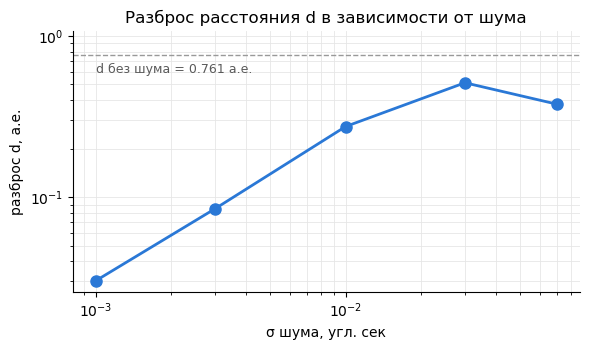

In [15]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.loglog(mc.index, mc['d_spread'], 'o-', color=SERIES_COLORS[0], lw=2, ms=8)
ax.axhline(d, color='0.6', lw=1, ls='--') # d из точных данных (раздел 7)
ax.text(mc.index[0], d*0.9, f'd без шума = {d:.3f} а.е.', color='0.35', fontsize=9, va='top')
ax.set_ylim(top=d*1.4)
ax.set_xlabel('σ шума, угл. сек')
ax.set_ylabel('разброс d, а.е.')
ax.set_title('Разброс расстояния d в зависимости от шума')
ax.grid(True, which='both', color='0.9', lw=0.6)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## 12. Реальные измерения

Те же шаги для реальных измерений серии 20260929 из файла `REAL_FILE` (итог ноутбука астрометрии).
Невязки аппроксимации — это фактически шум измерений, их полезно сравнить с формальными ошибками.

In [16]:
real = pd.read_csv(REAL_FILE)
print(f"{REAL_FILE}: {len(real)} положений, дуга {(real['JD'].max()-real['JD'].min())*1440:.0f} мин, "
      f"средние ошибки RA {real['ERR_RA'].mean():.3f}\", DEC {real['ERR_DEC'].mean():.3f}\"")
rows = []
for n in (2, 3):
    o = laplace_orbit(real, n=n)
    print(f"n = {n}: C = {o['coef']['C']:.3e}, решения (r, d): {[(round(a_, 4), round(b_, 4)) for a_, b_ in o['sols']]}")
    rows.append(dict(n=n, d=o.get('d'), **(o['el'] or {})))
    if n == POLY_DEG:
        real_fit = o['fit_res']
pd.DataFrame(rows).set_index('n')

/Users/ymax/Documents/coding/claude/nea_orb/24445_20260929_radec.csv: 9 положений, дуга 53 мин, средние ошибки RA 0.074", DEC 0.062"
n = 2: C = 5.284e-06, решения (r, d): [(np.float64(1.9078), np.float64(1.305))]
n = 3: C = -1.087e-06, решения (r, d): [(np.float64(6.3349), np.float64(-6.623))]


,d,a,e,i,Node,Peri,M
n,,,,,,,
2,1.304989,-0.004472,219.849273,35.430855,185.692577,199.953814,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


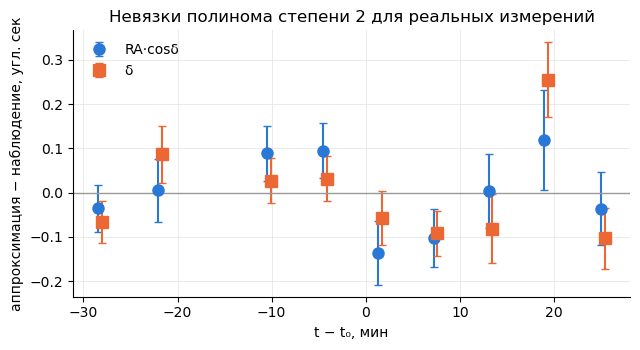

In [17]:
tmin = (real['JD'] - real['JD'].mean())*1440
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.errorbar(tmin, real_fit[:,0], yerr=real['ERR_RA'], fmt='o', color=SERIES_COLORS[0], ms=8, lw=1.5,
            capsize=3, label='RA·cosδ')
ax.errorbar(tmin+0.4, real_fit[:,1], yerr=real['ERR_DEC'], fmt='s', color=SERIES_COLORS[1], ms=8, lw=1.5,
            capsize=3, label='δ')
ax.axhline(0, color='0.6', lw=1)
ax.set_xlabel('t − t₀, мин')
ax.set_ylabel('аппроксимация − наблюдение, угл. сек')
ax.set_title(f'Невязки полинома степени {POLY_DEG} для реальных измерений')
ax.legend(frameon=False)
ax.grid(True, color='0.9', lw=0.6)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## Выводы

1. **На точных данных метод работает даже на дуге в 45 минут.** Расстояние определяется по
   суточному параллаксу: ускорение наблюдателя от вращения Земли в несколько раз больше солнечного
   и дает основную кривизну видимого пути (раздел 4). Элементы совпадают с MPCORB с точностью,
   ограниченной в основном степенью полинома (раздел 10).
2. **На дуге в одну ночь метод крайне чувствителен к шуму** (раздел 11). Разброс $d$ растет
   примерно пропорционально σ, а $a$ и $e$ еще чувствительнее: даже при σ = 0.001″ разброс $a$
   порядка 1 а.е. При шуме реальных измерений (~0.07″) решения в большинстве гиперболические.
3. **Реальная серия 20260929** (54 мин, 9 точек) по этой причине надежной орбиты не дает (раздел 12).
   Это ограничение данных, а не ошибка вычислений.
4. **Для настоящей предварительной орбиты нужна дуга в несколько ночей.** Но тогда топоцентрический
   вариант из этого ноутбука неприменим. Суточное вращение наблюдателя дает в $\mathbf D(t)$ колебание
   с периодом сутки, которое низкой степенью полинома на многодневной дуге не описать. Нужен
   геоцентрический вариант:
   - $\mathbf g$ — центр Земли;
   - направления исправляются за параллакс $\mathbf D_{geo} \propto d\,\mathbf D + (\mathbf g_{obs} - \mathbf g_\oplus)$
     с итерациями по $d$, начиная с первого решения.